# Self-Supervised Learning for Early Mango Leaf Stress & Disease Detection

This notebook builds a **self-supervised learning (SSL) framework** for detecting stress and disease in **mango (*Mangifera indica*) leaves** at an early stage, before symptoms are obvious to the naked eye.

**Why self-supervised learning?** Labeled agricultural disease datasets are small and expensive to build, but *unlabeled* field images are cheap to collect. SSL lets us pretrain a strong visual encoder on unlabeled mango leaf images (contrastive learning, SimCLR-style), and then use only a small amount of labeled data to fine-tune a classifier — and even to score "how far" a leaf's embedding is from healthy leaves, which acts as an **early stress indicator**.

## Pipeline
1. **Data** — Mango leaf images, auto-downloaded from Kaggle (`binhpt310/mango-combined-dataset`: 8 classes, ~40,000 images combined+augmented from MangoLeafBD/MLD24/other sources)
2. **SSL pretraining** — SimCLR contrastive learning on unlabeled mango leaves
3. **Downstream fine-tuning** — Linear probe + fine-tune for disease classification
4. **Evaluation** — Accuracy, confusion matrix, embedding visualization (t-SNE)
5. **Early stress scoring** — Distance-from-healthy-centroid in learned embedding space

Built for **local use**: every training stage (SSL pretraining, linear probe, fine-tuning) **checkpoints to
disk after every epoch** and **automatically resumes** from the last checkpoint if you re-run a cell or restart
the kernel — so you can stop and pick up training later without losing progress.

> Scope note: this notebook is deliberately restricted to **mango only**.


## 1. Setup

Requires `git` to be installed and on your PATH (used to clone the dataset repo in Section 2).


In [1]:
# If running in a fresh local environment, uncomment:
# !pip install torch torchvision scikit-learn matplotlib pillow tqdm -q

import os
import random
import glob
import math
import json
import shutil
import subprocess
import sys
import hashlib

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms, models

from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# All progress (dataset, model checkpoints) is written under these local folders,
# so re-running this notebook later picks up exactly where you left off.
DATA_ROOT = "data"
CHECKPOINT_DIR = "checkpoints"
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)


Using device: cuda


## 2. Dataset — Mango Leaf Images, Downloaded From Kaggle

This cell **automatically downloads** the
[`binhpt310/mango-combined-dataset`](https://www.kaggle.com/datasets/binhpt310/mango-combined-dataset)
("Combined Mango Leaf Disease Dataset") from Kaggle using `kagglehub` — a merged + augmented combination of
MangoLeafBD, MLD24, and another mango leaf disease dataset: **8 classes, ~40,000 images (5,000/class)**:
`Anthracnose, Bacterial Canker, Cutting Weevil, Die Back, Gall Midge, Healthy, Powdery Mildew, Sooty Mold`.

Note this dataset is built via heavy data augmentation on a smaller base (as few as ~500–2,500 originals per
class), so many images are augmented duplicates rather than fully independent samples — good for having more
data to iterate with, but keep that in mind when interpreting how much accuracy gains reflect real generalization
vs. memorizing augmentation patterns.

**One-time Kaggle auth setup** (required the first time you run this locally):
1. Create a Kaggle account if you don't have one, then go to *Account -> Create New API Token* to download `kaggle.json`.
2. Place it at `~/.kaggle/kaggle.json` (Linux/Mac) or `C:\\Users\\<you>\\.kaggle\\kaggle.json` (Windows), **or**
   set the `KAGGLE_USERNAME` and `KAGGLE_KEY` environment variables.
3. `kagglehub` caches the download locally (default `~/.cache/kagglehub`) — re-running this cell later reuses the
   cached copy instead of re-downloading, same "resume, don't repeat work" philosophy as the checkpoints below.
   At ~880MB zipped, the first download will take a few minutes.

If the download fails (no credentials set up yet, no internet), the notebook automatically falls back to a small
synthetic mango-leaf-like dataset so every downstream cell still runs — just re-run this cell once Kaggle access
is set up to switch to the real data.


In [2]:
# !pip install kagglehub -q

try:
    import kagglehub
    KAGGLEHUB_AVAILABLE = True
except ImportError:
    KAGGLEHUB_AVAILABLE = False
    print("'kagglehub' is not installed. Run:  pip install kagglehub")

KAGGLE_DATASET_SLUG = "binhpt310/mango-combined-dataset"

# Canonical class names (used for the synthetic fallback and as display labels).
MANGO_LEAF_BD_CLASSES = [
    "Anthracnose", "Bacterial Canker", "Cutting Weevil", "Die Back",
    "Gall Midge", "Healthy", "Powdery Mildew", "Sooty Mould",
]

# Loose keyword match instead of exact-string match, since different mango-disease dataset releases spell
# classes slightly differently (e.g. "Sooty Mould" vs "Sooty Mold") or vary capitalization/spacing.
MANGO_CLASS_KEYWORDS = [
    "anthracnose", "bacterial canker", "cutting weevil", "die back",
    "gall midge", "healthy", "powdery mildew", "sooty mo",  # "sooty mo" matches both mold/mould
]

DATA_DIR = None


def find_dataset_root(base_path, keywords=MANGO_CLASS_KEYWORDS, min_matches=4):
    """Walk the downloaded tree and find the folder whose immediate subfolders match known mango disease
    classes (kagglehub sometimes nests the actual class folders one or two levels deep)."""
    for dirpath, dirnames, _ in os.walk(base_path):
        lowered = [d.lower() for d in dirnames]
        matches = sum(1 for kw in keywords if any(kw in d for d in lowered))
        if matches >= min_matches:
            return dirpath
    return None


def download_mango_dataset(slug=KAGGLE_DATASET_SLUG):
    if not KAGGLEHUB_AVAILABLE:
        return None
    try:
        path = kagglehub.dataset_download(slug)
        print(f"Dataset ready at: {path}")
        return path
    except Exception as e:
        print(f"Kaggle download failed ({e}).")
        print("Check your ~/.kaggle/kaggle.json credentials (or KAGGLE_USERNAME/KAGGLE_KEY env vars) "
              "and internet connection.")
        return None


downloaded_path = download_mango_dataset()
if downloaded_path:
    DATA_DIR = find_dataset_root(downloaded_path)
    if DATA_DIR:
        print(f"Found class folders at: {DATA_DIR}")
    else:
        print("Downloaded the dataset but couldn't locate the expected class folders inside it — "
              "inspect the downloaded path manually and set DATA_DIR yourself if needed.")

USE_REAL_DATA = DATA_DIR is not None and len(glob.glob(os.path.join(DATA_DIR, "*", "*.*"))) > 0
print("Using real, Kaggle-downloaded mango dataset." if USE_REAL_DATA else "-> Falling back to synthetic demo data.")


Dataset ready at: C:\Users\ASUS\.cache\kagglehub\datasets\binhpt310\mango-combined-dataset\versions\1
Found class folders at: C:\Users\ASUS\.cache\kagglehub\datasets\binhpt310\mango-combined-dataset\versions\1\new_dataset_combined
Using real, Kaggle-downloaded mango dataset.


### 2.1 Synthetic fallback generator (only used if the Kaggle download didn't yield data)

Procedurally generates simple "leaf-like" images with class-specific blotches so the full pipeline can be
sanity-checked without real data. **Not a substitute for real training data.**


In [3]:
IMG_SIZE = 224


def make_synthetic_mango_dataset(root, class_names=MANGO_LEAF_BD_CLASSES, n_per_class=60,
                                  img_size=IMG_SIZE, seed=SEED):
    rng = random.Random(seed)
    os.makedirs(root, exist_ok=True)
    base_green = (34, 90, 34)
    class_colors = {
        "Anthracnose": (90, 40, 20), "Bacterial Canker": (60, 30, 10),
        "Cutting Weevil": (120, 90, 30), "Die Back": (70, 50, 20),
        "Gall Midge": (110, 60, 60), "Healthy": base_green,
        "Powdery Mildew": (200, 200, 200), "Sooty Mould": (30, 30, 30),
    }
    for cname in class_names:
        cdir = os.path.join(root, cname)
        os.makedirs(cdir, exist_ok=True)
        blotch_color = class_colors.get(cname, (100, 60, 60))
        n_blotches = 0 if "healthy" in cname.lower() else rng.randint(6, 16)
        for i in range(n_per_class):
            img = Image.new("RGB", (img_size, img_size), color=base_green)
            draw = ImageDraw.Draw(img)
            draw.line([(img_size // 2, 0), (img_size // 2, img_size)], fill=(20, 60, 20), width=4)
            for _ in range(n_blotches):
                x, y = rng.randint(0, img_size), rng.randint(0, img_size)
                r = rng.randint(4, 14)
                jitter = tuple(min(255, max(0, c + rng.randint(-15, 15))) for c in blotch_color)
                draw.ellipse([x - r, y - r, x + r, y + r], fill=jitter)
            img.save(os.path.join(cdir, f"{cname.replace(' ', '_')}_{i:03d}.png"))
    print(f"Synthetic mango dataset created at: {root}")


if not USE_REAL_DATA:
    DATA_DIR = os.path.join(DATA_ROOT, "synthetic_mango")
    if not (os.path.isdir(DATA_DIR) and glob.glob(os.path.join(DATA_DIR, "*", "*.*"))):
        make_synthetic_mango_dataset(DATA_DIR)
    USE_REAL_DATA = True

CLASS_NAMES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Dataset dir:", DATA_DIR)
print("Classes:", CLASS_NAMES)


Dataset dir: C:\Users\ASUS\.cache\kagglehub\datasets\binhpt310\mango-combined-dataset\versions\1\new_dataset_combined
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


## 3. Checkpoint / Resume Utilities

Every training loop below (SSL pretraining, linear probe, fine-tuning) uses these two helpers to **save model +
optimizer + training history to disk after every epoch**, and to **auto-resume** from the last saved epoch the
next time the cell runs. This means you can safely interrupt training (close the notebook, restart the kernel,
shut down your machine) and continue later just by re-running the same cell.

To force a clean restart for a given stage, delete its checkpoint file in `checkpoints/` (or pass `resume=False`).


In [4]:
def save_checkpoint(path, epoch, model, optimizer=None, scheduler=None, history=None, extra=None):
    ckpt = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict() if optimizer is not None else None,
        "scheduler_state": scheduler.state_dict() if scheduler is not None else None,
        "history": history,
        "extra": extra,
    }
    tmp_path = path + ".tmp"
    torch.save(ckpt, tmp_path)
    os.replace(tmp_path, path)  # atomic write so a crash mid-save can't corrupt the checkpoint


def load_checkpoint(path, model, optimizer=None, scheduler=None, device=device):
    if not os.path.isfile(path):
        return None
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optimizer_state") is not None:
        optimizer.load_state_dict(ckpt["optimizer_state"])
    if scheduler is not None and ckpt.get("scheduler_state") is not None:
        scheduler.load_state_dict(ckpt["scheduler_state"])
    print(f"Resumed '{path}' from epoch {ckpt['epoch']}")
    return ckpt


## 4. SimCLR-Style Augmentations

Self-supervised contrastive learning needs two **different augmented views** of the same leaf image. The model
learns to pull representations of the two views together, and push apart representations of different images.


In [5]:
class SimCLRTransform:
    """Produces two augmented views of the same mango leaf image for contrastive pretraining."""

    def __init__(self, img_size=IMG_SIZE):
        color_jitter = transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)
        self.transform = transforms.Compose([
            transforms.RandomResizedCrop(img_size, scale=(0.5, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomApply([color_jitter], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=5)], p=0.3),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ])

    def __call__(self, x):
        return self.transform(x), self.transform(x)


eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


## 5. Datasets

- `MangoUnlabeledDataset` — feeds pairs of augmented views for SSL pretraining (labels are ignored/not needed).
- `MangoLabeledDataset` — standard `(image, label)` pairs for downstream fine-tuning/evaluation.

**Leakage check + leak-safe split**: this "combined" dataset is heavily augmented from a smaller base of
originals, so it's plausible for near-identical/duplicate images to exist across the dataset. Splitting by
individual file (the naive approach) can let duplicates land in both train and test, which inflates test
accuracy without the model actually generalizing better. Below, we hash every image and group *exact*
byte-for-byte duplicates so a group is always kept together in the same split — this only catches exact
duplicates (not, say, a rotated near-duplicate), but it removes the most clear-cut leakage risk and reports how
many duplicate groups it found so you know whether this was actually a factor for your results.


In [6]:
def list_mango_images(data_dir, class_names=CLASS_NAMES):
    samples = []
    for label_idx, cname in enumerate(class_names):
        cdir = os.path.join(data_dir, cname)
        if not os.path.isdir(cdir):
            continue
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            for path in glob.glob(os.path.join(cdir, ext)):
                samples.append((path, label_idx))
    return samples


class MangoUnlabeledDataset(Dataset):
    """Returns two augmented views of each mango leaf image (labels unused, as in true SSL pretraining)."""

    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, _ = self.samples[idx]
        img = Image.open(path).convert("RGB")
        view1, view2 = self.transform(img)
        return view1, view2


class MangoLabeledDataset(Dataset):
    """Standard labeled dataset for downstream disease classification."""

    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        img = self.transform(img)
        return img, label


all_samples = list_mango_images(DATA_DIR)
print(f"Total mango leaf images found: {len(all_samples)}")


def hash_file(path, chunk_size=65536):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


print("Hashing images to detect exact duplicates (this takes a minute on 40k images)...")
hash_to_samples = {}
for path, label in tqdm(all_samples, desc="Hashing", file=sys.stdout):
    h = hash_file(path)
    hash_to_samples.setdefault(h, []).append((path, label))

n_dup_groups = sum(1 for v in hash_to_samples.values() if len(v) > 1)
n_dup_files = sum(len(v) for v in hash_to_samples.values() if len(v) > 1)
print(f"Found {n_dup_groups} exact-duplicate group(s) covering {n_dup_files} files "
      f"(out of {len(all_samples)} total) that will now be kept together in the same split.")

# Split by duplicate-group, not by individual file, so an exact duplicate can never end up split across
# train/val/test (which is the clearest form of train/test leakage in this kind of dataset).
groups = list(hash_to_samples.values())
random.shuffle(groups)

n_groups = len(groups)
n_train_groups = int(0.7 * n_groups)
n_val_groups = int(0.15 * n_groups)

train_samples = [s for g in groups[:n_train_groups] for s in g]
val_samples = [s for g in groups[n_train_groups:n_train_groups + n_val_groups] for s in g]
test_samples = [s for g in groups[n_train_groups + n_val_groups:] for s in g]

print(f"train={len(train_samples)}  val={len(val_samples)}  test={len(test_samples)}  "
      f"(split by {n_groups} dedup groups, so exact duplicates can't leak across splits)")

all_samples = train_samples + val_samples + test_samples  # re-combined, still covers every image, dedup-safe
random.shuffle(all_samples)

ssl_dataset = MangoUnlabeledDataset(all_samples, SimCLRTransform())  # SSL can use ALL images, labels ignored

# num_workers=0 runs data loading in the main process. This is the safest default for notebooks — using
# num_workers>0 in Jupyter (especially on Windows/macOS) can silently HANG with zero output while worker
# processes spawn, which looks exactly like "training but no progress". Once you've confirmed training runs
# and prints progress with num_workers=0, you can try raising it (e.g. to 2 or 4) for a speedup.
NUM_WORKERS = 0
SSL_BATCH_SIZE = 128  # real-training default; SimCLR benefits from larger batches (more negatives per step).
                      # Drop to 32-64 if you hit GPU out-of-memory errors.
ssl_loader = DataLoader(ssl_dataset, batch_size=SSL_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
                         drop_last=True)

print(f"ssl_loader: {len(ssl_dataset)} images -> {len(ssl_loader)} batches/epoch "
      f"(batch_size={ssl_loader.batch_size}, num_workers={NUM_WORKERS})")
if len(ssl_loader) == 0:
    print("WARNING: 0 batches per epoch — you have fewer images than batch_size (drop_last=True discards the "
          "remainder). Lower batch_size above, or add more images, or pretrain_simclr will silently do nothing.")


Total mango leaf images found: 40000
Hashing images to detect exact duplicates (this takes a minute on 40k images)...


Hashing:   0%|          | 0/40000 [00:00<?, ?it/s]

Found 10018 exact-duplicate group(s) covering 20101 files (out of 40000 total) that will now be kept together in the same split.
train=28012  val=6011  test=5977  (split by 29917 dedup groups, so exact duplicates can't leak across splits)
ssl_loader: 40000 images -> 312 batches/epoch (batch_size=128, num_workers=0)


## 6. Model — Configurable Backbone + Projection Head (SimCLR)

The encoder is the reusable feature extractor — swap `BACKBONE` below to trade off speed vs. representation
quality. `resnet18` is fast and what the rest of this notebook was tuned with; `resnet50` has ~2x the capacity
and often gives a measurably better embedding space (worth trying once SSL loss plateaus with resnet18, as
happened around epoch ~100-150 in the run above). The projection head is only used during contrastive
pretraining and discarded afterwards, per the SimCLR recipe.


In [7]:
BACKBONE = "resnet18"  # "resnet18" (fast, default) or "resnet50" (slower, usually better embeddings)

_BACKBONE_FACTORIES = {
    "resnet18": (models.resnet18, models.ResNet18_Weights.DEFAULT),
    "resnet50": (models.resnet50, models.ResNet50_Weights.DEFAULT),
}


class Encoder(nn.Module):
    """Configurable ResNet backbone (no classification head) -> feature vector per image."""

    def __init__(self, backbone_name=BACKBONE, pretrained_imagenet=True):
        super().__init__()
        factory, default_weights = _BACKBONE_FACTORIES[backbone_name]
        weights = default_weights if pretrained_imagenet else None
        backbone = factory(weights=weights)
        self.feature_dim = backbone.fc.in_features  # 512 for resnet18, 2048 for resnet50
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.backbone_name = backbone_name

    def forward(self, x):
        return self.backbone(x)


class ProjectionHead(nn.Module):
    """MLP projection head used during SSL pretraining (SimCLR/BYOL-style).

    Includes BatchNorm1d after the hidden layer, matching the original SimCLR/BYOL papers — this is one of
    the mechanisms that helps prevent representation collapse (the encoder settling on a near-constant output
    for every input, which trivially drives the SSL loss toward its minimum without learning anything useful).
    """

    def __init__(self, in_dim, hidden_dim=512, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        return self.net(x)


class SimCLRModel(nn.Module):
    def __init__(self, backbone_name=BACKBONE, pretrained_imagenet=True, proj_dim=128):
        super().__init__()
        self.encoder = Encoder(backbone_name=backbone_name, pretrained_imagenet=pretrained_imagenet)
        self.projector = ProjectionHead(self.encoder.feature_dim, out_dim=proj_dim)

    def forward(self, x):
        h = self.encoder(x)          # representation used downstream
        z = self.projector(h)        # projection used only for contrastive loss
        return h, z


## 7. NT-Xent Contrastive Loss

The normalized temperature-scaled cross-entropy loss (NT-Xent) used in SimCLR: for each image, its two augmented
views should be close in embedding space, and far from every other image (and its views) in the batch.


In [8]:
def nt_xent_loss(z1, z2, temperature=0.5):
    batch_size = z1.size(0)
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)

    representations = torch.cat([z1, z2], dim=0)             # (2N, D)
    similarity_matrix = torch.matmul(representations, representations.T)  # (2N, 2N)

    labels = torch.arange(batch_size, device=z1.device)
    labels = torch.cat([labels + batch_size, labels], dim=0)  # positive pair index for each row

    mask = torch.eye(2 * batch_size, dtype=torch.bool, device=z1.device)
    similarity_matrix.masked_fill_(mask, -9e15)  # remove self-similarity

    similarity_matrix = similarity_matrix / temperature
    loss = F.cross_entropy(similarity_matrix, labels)
    return loss


## 7b. Alternative: BYOL (no negative pairs — better for small batch sizes)

SimCLR's contrastive loss relies on having many *negative* examples in each batch to push apart — with
`batch_size=32` that's a weak signal, which is a likely reason the SSL loss above plateaus/oscillates instead
of steadily decreasing past ~100 epochs. **BYOL** (Bootstrap Your Own Latent) sidesteps this: it trains an
"online" network to predict the output of a slowly-updated "target" network (an exponential moving average of
the online weights), using only positive pairs — no negatives, no large-batch requirement. It's a strong
alternative worth trying if you want to push representation quality further without a bigger GPU/batch size.

Both `SimCLRModel`/`pretrain_simclr` and `BYOLModel`/`pretrain_byol` produce a plain `Encoder` you can plug into
the exact same downstream classification and stress-scoring code below — pick whichever ends up with the
better linear-probe accuracy or embedding separation for your data.


In [9]:
class BYOLPredictor(nn.Module):
    """Extra MLP only on the online branch, per the BYOL paper — this asymmetry is what prevents collapse."""

    def __init__(self, in_dim, hidden_dim=512, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim),
        )

    def forward(self, x):
        return self.net(x)


class BYOLModel(nn.Module):
    def __init__(self, backbone_name=BACKBONE, pretrained_imagenet=True, proj_dim=128, momentum=0.996):
        super().__init__()
        self.momentum = momentum

        self.online_encoder = Encoder(backbone_name=backbone_name, pretrained_imagenet=pretrained_imagenet)
        self.online_projector = ProjectionHead(self.online_encoder.feature_dim, out_dim=proj_dim)
        self.predictor = BYOLPredictor(proj_dim, out_dim=proj_dim)

        self.target_encoder = Encoder(backbone_name=backbone_name, pretrained_imagenet=pretrained_imagenet)
        self.target_projector = ProjectionHead(self.target_encoder.feature_dim, out_dim=proj_dim)
        self._init_target()

    def _init_target(self):
        for p_online, p_target in zip(self.online_encoder.parameters(), self.target_encoder.parameters()):
            p_target.data.copy_(p_online.data)
            p_target.requires_grad = False
        for p_online, p_target in zip(self.online_projector.parameters(), self.target_projector.parameters()):
            p_target.data.copy_(p_online.data)
            p_target.requires_grad = False

    @torch.no_grad()
    def update_target(self):
        for p_online, p_target in zip(self.online_encoder.parameters(), self.target_encoder.parameters()):
            p_target.data = self.momentum * p_target.data + (1 - self.momentum) * p_online.data
        for p_online, p_target in zip(self.online_projector.parameters(), self.target_projector.parameters()):
            p_target.data = self.momentum * p_target.data + (1 - self.momentum) * p_online.data

    def forward(self, view1, view2):
        # online branch sees both views and predicts the target branch's output for the *other* view
        online_pred1 = self.predictor(self.online_projector(self.online_encoder(view1)))
        online_pred2 = self.predictor(self.online_projector(self.online_encoder(view2)))
        with torch.no_grad():
            target_proj1 = self.target_projector(self.target_encoder(view1))
            target_proj2 = self.target_projector(self.target_encoder(view2))
        return online_pred1, online_pred2, target_proj1, target_proj2


def byol_loss(online_pred, target_proj):
    online_pred = F.normalize(online_pred, dim=-1)
    target_proj = F.normalize(target_proj, dim=-1)
    return 2 - 2 * (online_pred * target_proj).sum(dim=-1).mean()


def pretrain_byol(model, loader, epochs=10, lr=3e-4, device=device,
                   checkpoint_path=os.path.join(CHECKPOINT_DIR, "byol_pretrain.pt"), resume=True):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    start_epoch = 0
    history = []

    if resume:
        ckpt = load_checkpoint(checkpoint_path, model, optimizer, scheduler, device)
        if ckpt is not None:
            start_epoch = ckpt["epoch"]
            history = ckpt.get("history") or []

    if start_epoch >= epochs:
        print(f"Checkpoint already at epoch {start_epoch} >= target {epochs} epochs; nothing to do. "
              f"Increase 'epochs' to keep training.", flush=True)
        return history

    n_batches = len(loader)
    print(f"Starting BYOL pretraining on {device}: epoch {start_epoch + 1} -> {epochs}, "
          f"{n_batches} batches/epoch, batch_size={loader.batch_size}", flush=True)
    if n_batches == 0:
        print("ABORTING: 0 batches/epoch — see the ssl_loader diagnostic above.", flush=True)
        return history

    model.train()
    for epoch in range(start_epoch, epochs):
        epoch_loss = 0.0
        print_every = max(1, n_batches // 10)
        pbar = tqdm(loader, desc=f"BYOL epoch {epoch + 1}/{epochs}", leave=False, file=sys.stdout)
        for batch_idx, (view1, view2) in enumerate(pbar, start=1):
            view1, view2 = view1.to(device), view2.to(device)

            online_pred1, online_pred2, target_proj1, target_proj2 = model(view1, view2)
            loss = (byol_loss(online_pred1, target_proj2) + byol_loss(online_pred2, target_proj1)) / 2

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            model.update_target()  # EMA update of the target network (no grad)

            epoch_loss += loss.item()
            pbar.set_postfix(batch_loss=f"{loss.item():.4f}")

            if batch_idx % print_every == 0 or batch_idx == n_batches:
                print(f"  epoch {epoch + 1}/{epochs}  batch {batch_idx}/{n_batches}  "
                      f"batch_loss={loss.item():.4f}", flush=True)

        scheduler.step()
        avg_loss = epoch_loss / max(1, n_batches)
        history.append(avg_loss)
        print(f"[BYOL] epoch {epoch + 1}/{epochs}  loss={avg_loss:.4f}", flush=True)

        save_checkpoint(checkpoint_path, epoch + 1, model, optimizer, scheduler, history=history)

    print(f"Progress saved to '{checkpoint_path}'.", flush=True)
    return history


## 8. Self-Supervised Pretraining (checkpointed, resumable)

Trains the encoder purely on **unlabeled** mango leaf images using contrastive learning. No disease labels are
used in this stage. Set `SSL_METHOD` to `"simclr"` or `"byol"` (see Section 7b) — whichever you pick, this cell
saves progress to its own checkpoint file after every epoch and resumes automatically on re-run, and produces a
single `trained_encoder` that every downstream cell (classification, t-SNE, stress scoring) uses from here on.

**Important**: every checkpoint from this cell onward is named using `RUN_TAG = f"{SSL_METHOD}_{BACKBONE}"`.
This means changing either setting and re-running always trains a *fresh* model for that combination — it
won't silently reload a checkpoint trained under a different config and report stale results, which is what
would happen (identical metrics on every run) if the filenames were fixed instead of tagged.


In [10]:
def pretrain_simclr(model, loader, epochs=10, lr=3e-4, temperature=0.5, device=device,
                     checkpoint_path=os.path.join(CHECKPOINT_DIR, "ssl_pretrain.pt"), resume=True):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    start_epoch = 0
    history = []

    if resume:
        ckpt = load_checkpoint(checkpoint_path, model, optimizer, scheduler, device)
        if ckpt is not None:
            start_epoch = ckpt["epoch"]
            history = ckpt.get("history") or []

    if start_epoch >= epochs:
        print(f"Checkpoint already at epoch {start_epoch} >= target {epochs} epochs; nothing to do. "
              f"Increase 'epochs' to keep training.", flush=True)
        return history

    n_batches = len(loader)
    print(f"Starting SSL pretraining on {device}: epoch {start_epoch + 1} -> {epochs}, "
          f"{n_batches} batches/epoch, batch_size={loader.batch_size}", flush=True)

    if n_batches == 0:
        print("ABORTING: the data loader has 0 batches per epoch, so there is nothing to train on and no "
              "output would ever be printed. This means your dataset has fewer images than batch_size "
              "(drop_last=True drops the remainder). Fix by lowering batch_size when building ssl_loader, or "
              "by adding more images to DATA_DIR, then re-run this cell.", flush=True)
        return history

    model.train()
    for epoch in range(start_epoch, epochs):
        epoch_loss = 0.0
        print_every = max(1, n_batches // 10)  # ~10 manual progress lines per epoch, as a tqdm-independent backup
        pbar = tqdm(loader, desc=f"SSL epoch {epoch + 1}/{epochs}", leave=False, file=sys.stdout)
        for batch_idx, (view1, view2) in enumerate(pbar, start=1):
            view1, view2 = view1.to(device), view2.to(device)

            _, z1 = model(view1)
            _, z2 = model(view2)

            loss = nt_xent_loss(z1, z2, temperature=temperature)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            pbar.set_postfix(batch_loss=f"{loss.item():.4f}")

            if batch_idx % print_every == 0 or batch_idx == n_batches:
                print(f"  epoch {epoch + 1}/{epochs}  batch {batch_idx}/{n_batches}  "
                      f"batch_loss={loss.item():.4f}", flush=True)

        scheduler.step()
        avg_loss = epoch_loss / max(1, n_batches)
        history.append(avg_loss)
        print(f"[SSL] epoch {epoch + 1}/{epochs}  contrastive_loss={avg_loss:.4f}", flush=True)

        save_checkpoint(checkpoint_path, epoch + 1, model, optimizer, scheduler, history=history)

    print(f"Progress saved to '{checkpoint_path}'.", flush=True)
    return history


RUN_TAG = 'simclr_resnet18'  (checkpoints for this config are suffixed with this tag)
Resumed 'checkpoints\ssl_pretrain_simclr_resnet18.pt' from epoch 139
Starting SSL pretraining on cuda: epoch 140 -> 150, 312 batches/epoch, batch_size=128


SSL epoch 140/150:   0%|          | 0/312 [00:00<?, ?it/s]

  epoch 140/150  batch 31/312  batch_loss=3.5737
  epoch 140/150  batch 62/312  batch_loss=3.5743
  epoch 140/150  batch 93/312  batch_loss=3.5748
  epoch 140/150  batch 124/312  batch_loss=3.5713
  epoch 140/150  batch 155/312  batch_loss=3.5731
  epoch 140/150  batch 186/312  batch_loss=3.5735
  epoch 140/150  batch 217/312  batch_loss=3.5726
  epoch 140/150  batch 248/312  batch_loss=3.5730
  epoch 140/150  batch 279/312  batch_loss=3.5716
  epoch 140/150  batch 310/312  batch_loss=3.5860
  epoch 140/150  batch 312/312  batch_loss=3.5717
[SSL] epoch 140/150  contrastive_loss=3.5736


SSL epoch 141/150:   0%|          | 0/312 [00:00<?, ?it/s]

  epoch 141/150  batch 31/312  batch_loss=3.5722
  epoch 141/150  batch 62/312  batch_loss=3.5727
  epoch 141/150  batch 93/312  batch_loss=3.5705
  epoch 141/150  batch 124/312  batch_loss=3.5726
  epoch 141/150  batch 155/312  batch_loss=3.5738
  epoch 141/150  batch 186/312  batch_loss=3.5726
  epoch 141/150  batch 217/312  batch_loss=3.5736
  epoch 141/150  batch 248/312  batch_loss=3.5709
  epoch 141/150  batch 279/312  batch_loss=3.5748
  epoch 141/150  batch 310/312  batch_loss=3.5732
  epoch 141/150  batch 312/312  batch_loss=3.5724
[SSL] epoch 141/150  contrastive_loss=3.5732


SSL epoch 142/150:   0%|          | 0/312 [00:00<?, ?it/s]

... (13 outputs left out)

SSL epoch 149/150:   0%|          | 0/312 [00:00<?, ?it/s]

  epoch 149/150  batch 31/312  batch_loss=3.5752
  epoch 149/150  batch 62/312  batch_loss=3.5723
  epoch 149/150  batch 93/312  batch_loss=3.5726
  epoch 149/150  batch 124/312  batch_loss=3.5758
  epoch 149/150  batch 155/312  batch_loss=3.5706
  epoch 149/150  batch 186/312  batch_loss=3.5764
  epoch 149/150  batch 217/312  batch_loss=3.5708
  epoch 149/150  batch 248/312  batch_loss=3.5730
  epoch 149/150  batch 279/312  batch_loss=3.5715
  epoch 149/150  batch 310/312  batch_loss=3.5772
  epoch 149/150  batch 312/312  batch_loss=3.5736
[SSL] epoch 149/150  contrastive_loss=3.5734


SSL epoch 150/150:   0%|          | 0/312 [00:00<?, ?it/s]

  epoch 150/150  batch 31/312  batch_loss=3.5723
  epoch 150/150  batch 62/312  batch_loss=3.5732
  epoch 150/150  batch 93/312  batch_loss=3.5762
  epoch 150/150  batch 124/312  batch_loss=3.5757
  epoch 150/150  batch 155/312  batch_loss=3.5897
  epoch 150/150  batch 186/312  batch_loss=3.5735
  epoch 150/150  batch 217/312  batch_loss=3.5703
  epoch 150/150  batch 248/312  batch_loss=3.5841
  epoch 150/150  batch 279/312  batch_loss=3.5747
  epoch 150/150  batch 310/312  batch_loss=3.5752
  epoch 150/150  batch 312/312  batch_loss=3.5731
[SSL] epoch 150/150  contrastive_loss=3.5740
Progress saved to 'checkpoints\ssl_pretrain_simclr_resnet18.pt'.


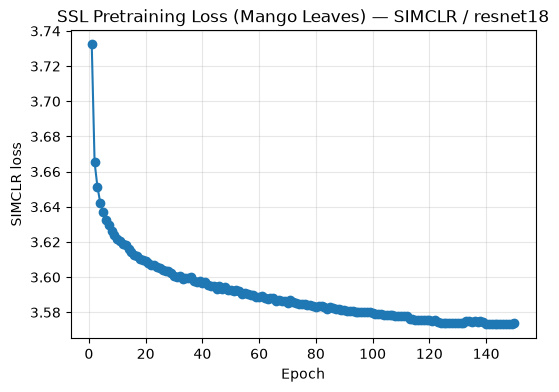

In [11]:
EPOCHS_SSL = 150  # real-training default for the full 40k-image dataset; re-run this cell any time to keep
                  # training from the last saved checkpoint (drop to ~10-20 first if you just want a quick
                  # smoke-test that everything runs before committing to a long run)
SSL_METHOD = "simclr"  # "simclr" (needs a decent batch size) or "byol" (works well even at batch_size=32)

# Tag every checkpoint (SSL + all downstream stages below) with the current method+backbone, so switching
# either one always trains a fresh model instead of silently resuming/reloading a checkpoint that belongs to
# a *different* config (which is what causes "different settings give identical metrics" - it's actually just
# reloading the old result).
RUN_TAG = f"{SSL_METHOD}_{BACKBONE}"
print(f"RUN_TAG = '{RUN_TAG}'  (checkpoints for this config are suffixed with this tag)")

if SSL_METHOD == "simclr":
    ssl_model = SimCLRModel(backbone_name=BACKBONE, pretrained_imagenet=True, proj_dim=128)
    ssl_history = pretrain_simclr(ssl_model, ssl_loader, epochs=EPOCHS_SSL,
                                   checkpoint_path=os.path.join(CHECKPOINT_DIR, f"ssl_pretrain_{RUN_TAG}.pt"))
    trained_encoder = ssl_model.encoder
elif SSL_METHOD == "byol":
    byol_model = BYOLModel(backbone_name=BACKBONE, pretrained_imagenet=True, proj_dim=128)
    ssl_history = pretrain_byol(byol_model, ssl_loader, epochs=EPOCHS_SSL,
                                 checkpoint_path=os.path.join(CHECKPOINT_DIR, f"byol_pretrain_{RUN_TAG}.pt"))
    trained_encoder = byol_model.online_encoder
else:
    raise ValueError(f"Unknown SSL_METHOD: {SSL_METHOD!r}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(ssl_history) + 1), ssl_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel(f"{SSL_METHOD.upper()} loss")
plt.title(f"SSL Pretraining Loss (Mango Leaves) — {SSL_METHOD.upper()} / {BACKBONE}")
plt.grid(alpha=0.3)
plt.show()


## 8b. Collapse Check

A sanity check before spending time on downstream training: if `SSL_METHOD="byol"`'s loss dropped very fast
(e.g. to ~0.03 within the first handful of epochs and flat from there), that can mean the encoder found a
degenerate shortcut — outputting nearly the same embedding for every image — rather than actually learning
disease-relevant features. That trivially drives the loss down without anything useful being learned. This
cell checks for that directly by looking at how spread out the embeddings of a batch of *different* images
actually are; near-zero spread means collapse regardless of how low the SSL loss got.


In [12]:
@torch.no_grad()
def check_embedding_collapse(encoder, loader, device=device, n_batches=3):
    """Embeds a few batches of genuinely different images and reports how spread out they are.
    Near-zero average std / near-1.0 average pairwise cosine similarity means the encoder is outputting
    almost the same vector for every image — i.e. collapsed, regardless of how low the SSL loss got."""
    encoder.eval()
    all_feats = []
    for i, (view1, _) in enumerate(loader):
        if i >= n_batches:
            break
        feats = encoder(view1.to(device))
        all_feats.append(feats.cpu())
    feats = torch.cat(all_feats, dim=0)

    normed = F.normalize(feats, dim=1)
    sim_matrix = normed @ normed.T
    mask = ~torch.eye(sim_matrix.size(0), dtype=torch.bool)
    avg_pairwise_cos_sim = sim_matrix[mask].mean().item()
    avg_feature_std = feats.std(dim=0).mean().item()

    print(f"Embedded {feats.size(0)} images -> avg pairwise cosine similarity: {avg_pairwise_cos_sim:.4f}  "
          f"(near 1.0 = collapsed, near 0 = healthy/diverse)")
    print(f"Average per-dimension std across the batch: {avg_feature_std:.4f}  (near 0 = collapsed)")

    if avg_pairwise_cos_sim > 0.9:
        print("WARNING: embeddings look collapsed — nearly every image maps to almost the same vector. "
              "Downstream classification accuracy will likely be poor/near-chance despite a low SSL loss. "
              "Consider: lower learning rate, a smaller momentum for BYOL's target network (e.g. 0.99 instead "
              "of 0.996), stronger/more varied augmentations, or switching back to SimCLR.")
    else:
        print("Embeddings look reasonably diverse across different images — not an obvious collapse.")


check_embedding_collapse(trained_encoder, ssl_loader)


Embedded 384 images -> avg pairwise cosine similarity: 0.2911  (near 1.0 = collapsed, near 0 = healthy/diverse)
Average per-dimension std across the batch: 0.5981  (near 0 = collapsed)
Embeddings look reasonably diverse across different images — not an obvious collapse.


## 9. Downstream Task — Mango Disease Classification

Now we reuse the **pretrained encoder** and attach a small classification head, training it on the (much
smaller) labeled split. Two modes are supported:
- **Linear probe**: freeze the encoder, train only the linear classifier (tests representation quality directly).
- **Fine-tune**: unfreeze the encoder too, with a low learning rate, for the best final accuracy.

Both stages checkpoint to disk after every epoch and resume automatically, same as SSL pretraining above.


In [13]:
class MangoClassifier(nn.Module):
    def __init__(self, encoder, num_classes, freeze_encoder=True):
        super().__init__()
        self.encoder = encoder
        self.freeze_encoder = freeze_encoder
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
        self.classifier = nn.Linear(encoder.feature_dim, num_classes)

    def forward(self, x):
        with torch.set_grad_enabled(not self.freeze_encoder):
            feats = self.encoder(x)
        return self.classifier(feats)


train_ds = MangoLabeledDataset(train_samples, eval_transform)
val_ds = MangoLabeledDataset(val_samples, eval_transform)
test_ds = MangoLabeledDataset(test_samples, eval_transform)

DOWNSTREAM_BATCH_SIZE = 64  # real-training default for the labeled classification stage
train_loader = DataLoader(train_ds, batch_size=DOWNSTREAM_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=DOWNSTREAM_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=DOWNSTREAM_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Labeled splits -> train: {len(train_ds)}  val: {len(val_ds)}  test: {len(test_ds)}")


Labeled splits -> train: 28012  val: 6011  test: 5977


In [14]:
@torch.no_grad()
def evaluate_accuracy(model, loader, device=device):
    model.eval()
    correct, total = 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return correct / max(1, total)


@torch.no_grad()
def evaluate_loss_and_accuracy(model, loader, criterion, device=device):
    """Returns (avg_loss, accuracy) on a loader — val_loss is what actually reveals overfitting
    (train_loss falling while val_loss rises/plateaus), which val_acc alone can mask."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / max(1, total), correct / max(1, total)


def train_classifier(model, train_loader, val_loader, epochs=10, lr=1e-3, device=device,
                      checkpoint_path="checkpoints/classifier.pt", best_path=None, resume=True):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val_acc = 0.0

    if resume:
        ckpt = load_checkpoint(checkpoint_path, model, optimizer, device=device)
        if ckpt is not None:
            start_epoch = ckpt["epoch"]
            history = ckpt.get("history") or history
            history.setdefault("val_loss", [])  # older checkpoints (pre-val_loss tracking) won't have this key
            best_val_acc = (ckpt.get("extra") or {}).get("best_val_acc", 0.0)

    if start_epoch >= epochs:
        print(f"Checkpoint already at epoch {start_epoch} >= target {epochs} epochs; nothing to do. "
              f"Increase 'epochs' to keep training.", flush=True)
        return history

    n_batches = len(train_loader)
    print(f"Starting downstream training on {device}: epoch {start_epoch + 1} -> {epochs}, "
          f"{n_batches} batches/epoch, batch_size={train_loader.batch_size}", flush=True)

    if n_batches == 0:
        print("ABORTING: train_loader has 0 batches — your labeled training split is empty or smaller than "
              "batch_size. Check DATA_DIR / your train/val/test split sizes.", flush=True)
        return history

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss = 0.0
        print_every = max(1, n_batches // 10)
        pbar = tqdm(train_loader, desc=f"Downstream epoch {epoch + 1}/{epochs}", leave=False, file=sys.stdout)
        for batch_idx, (imgs, labels) in enumerate(pbar, start=1):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            pbar.set_postfix(batch_loss=f"{loss.item():.4f}")

            if batch_idx % print_every == 0 or batch_idx == n_batches:
                print(f"  epoch {epoch + 1}/{epochs}  batch {batch_idx}/{n_batches}  "
                      f"batch_loss={loss.item():.4f}", flush=True)

        val_loss, val_acc = evaluate_loss_and_accuracy(model, val_loader, criterion, device)
        avg_loss = running_loss / max(1, n_batches)
        history["train_loss"].append(avg_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        is_best = val_acc > best_val_acc
        best_val_acc = max(best_val_acc, val_acc)

        print(f"[Downstream] epoch {epoch + 1}/{epochs}  train_loss={avg_loss:.4f}  "
              f"val_loss={val_loss:.4f}  val_acc={val_acc:.3f}"
              + ("  <- best so far" if is_best else ""), flush=True)

        save_checkpoint(checkpoint_path, epoch + 1, model, optimizer, history=history,
                         extra={"best_val_acc": best_val_acc})
        if is_best and best_path:
            save_checkpoint(best_path, epoch + 1, model, optimizer, history=history,
                             extra={"best_val_acc": best_val_acc})

    print(f"Best validation accuracy so far: {best_val_acc:.3f}  (checkpoint: {checkpoint_path})", flush=True)
    return history


In [15]:
# Stage 1: Linear probe (frozen encoder) - directly measures SSL representation quality
LINEAR_PROBE_EPOCHS = 30  # real-training default
linear_model = MangoClassifier(trained_encoder, num_classes=len(CLASS_NAMES), freeze_encoder=True)
linear_history = train_classifier(
    linear_model, train_loader, val_loader, epochs=LINEAR_PROBE_EPOCHS, lr=1e-3,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, f"linear_probe_{RUN_TAG}.pt"),
)


Starting downstream training on cuda: epoch 1 -> 30, 438 batches/epoch, batch_size=64


Downstream epoch 1/30:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 1/30  batch 43/438  batch_loss=0.9909
  epoch 1/30  batch 86/438  batch_loss=0.6171
  epoch 1/30  batch 129/438  batch_loss=0.3747
  epoch 1/30  batch 172/438  batch_loss=0.3562
  epoch 1/30  batch 215/438  batch_loss=0.2732
  epoch 1/30  batch 258/438  batch_loss=0.1881
  epoch 1/30  batch 301/438  batch_loss=0.2401
  epoch 1/30  batch 344/438  batch_loss=0.2255
  epoch 1/30  batch 387/438  batch_loss=0.2071
  epoch 1/30  batch 430/438  batch_loss=0.2293
  epoch 1/30  batch 438/438  batch_loss=0.1543
[Downstream] epoch 1/30  train_loss=0.4409  val_loss=0.1524  val_acc=0.957  <- best so far


Downstream epoch 2/30:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 2/30  batch 43/438  batch_loss=0.1690
  epoch 2/30  batch 86/438  batch_loss=0.3034
  epoch 2/30  batch 129/438  batch_loss=0.1628
  epoch 2/30  batch 172/438  batch_loss=0.0851
  epoch 2/30  batch 215/438  batch_loss=0.1456
  epoch 2/30  batch 258/438  batch_loss=0.2924
  epoch 2/30  batch 301/438  batch_loss=0.3291
  epoch 2/30  batch 344/438  batch_loss=0.0861
  epoch 2/30  batch 387/438  batch_loss=0.1171
  epoch 2/30  batch 430/438  batch_loss=0.1574
  epoch 2/30  batch 438/438  batch_loss=0.0825
[Downstream] epoch 2/30  train_loss=0.1540  val_loss=0.1257  val_acc=0.959  <- best so far


Downstream epoch 3/30:   0%|          | 0/438 [00:00<?, ?it/s]

... (51 outputs left out)

Downstream epoch 29/30:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 29/30  batch 43/438  batch_loss=0.0694
  epoch 29/30  batch 86/438  batch_loss=0.0313
  epoch 29/30  batch 129/438  batch_loss=0.0790
  epoch 29/30  batch 172/438  batch_loss=0.0153
  epoch 29/30  batch 215/438  batch_loss=0.0614
  epoch 29/30  batch 258/438  batch_loss=0.0879
  epoch 29/30  batch 301/438  batch_loss=0.0238
  epoch 29/30  batch 344/438  batch_loss=0.0432
  epoch 29/30  batch 387/438  batch_loss=0.0518
  epoch 29/30  batch 430/438  batch_loss=0.0410
  epoch 29/30  batch 438/438  batch_loss=0.0294
[Downstream] epoch 29/30  train_loss=0.0721  val_loss=0.0807  val_acc=0.974


Downstream epoch 30/30:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 30/30  batch 43/438  batch_loss=0.0930
  epoch 30/30  batch 86/438  batch_loss=0.1308
  epoch 30/30  batch 129/438  batch_loss=0.1029
  epoch 30/30  batch 172/438  batch_loss=0.0382
  epoch 30/30  batch 215/438  batch_loss=0.0720
  epoch 30/30  batch 258/438  batch_loss=0.0448
  epoch 30/30  batch 301/438  batch_loss=0.0170
  epoch 30/30  batch 344/438  batch_loss=0.0483
  epoch 30/30  batch 387/438  batch_loss=0.0280
  epoch 30/30  batch 430/438  batch_loss=0.1106
  epoch 30/30  batch 438/438  batch_loss=0.0856
[Downstream] epoch 30/30  train_loss=0.0695  val_loss=0.0793  val_acc=0.975
Best validation accuracy so far: 0.975  (checkpoint: checkpoints\linear_probe_simclr_resnet18.pt)


In [16]:
# Stage 2 (optional): Fine-tune the full network with a low LR for best accuracy
FINETUNE_EPOCHS = 20  # real-training default; fine-tuning usually needs fewer epochs than the linear probe
finetune_model = MangoClassifier(trained_encoder, num_classes=len(CLASS_NAMES), freeze_encoder=False)
finetune_history = train_classifier(
    finetune_model, train_loader, val_loader, epochs=FINETUNE_EPOCHS, lr=1e-4,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, f"finetune_{RUN_TAG}.pt"),
    best_path=os.path.join(CHECKPOINT_DIR, f"finetune_best_{RUN_TAG}.pt"),
)


Starting downstream training on cuda: epoch 1 -> 20, 438 batches/epoch, batch_size=64


Downstream epoch 1/20:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 1/20  batch 43/438  batch_loss=1.9281
  epoch 1/20  batch 86/438  batch_loss=1.7794
  epoch 1/20  batch 129/438  batch_loss=1.6261
  epoch 1/20  batch 172/438  batch_loss=1.5478
  epoch 1/20  batch 215/438  batch_loss=1.4564
  epoch 1/20  batch 258/438  batch_loss=1.2475
  epoch 1/20  batch 301/438  batch_loss=1.1392
  epoch 1/20  batch 344/438  batch_loss=1.1675
  epoch 1/20  batch 387/438  batch_loss=1.0090
  epoch 1/20  batch 430/438  batch_loss=0.9848
  epoch 1/20  batch 438/438  batch_loss=1.0145
[Downstream] epoch 1/20  train_loss=1.4379  val_loss=0.8530  val_acc=0.919  <- best so far


Downstream epoch 2/20:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 2/20  batch 43/438  batch_loss=0.8982
  epoch 2/20  batch 86/438  batch_loss=0.9168
  epoch 2/20  batch 129/438  batch_loss=0.9295
  epoch 2/20  batch 172/438  batch_loss=0.8464
  epoch 2/20  batch 215/438  batch_loss=0.6737
  epoch 2/20  batch 258/438  batch_loss=0.7079
  epoch 2/20  batch 301/438  batch_loss=0.6620
  epoch 2/20  batch 344/438  batch_loss=0.5686
  epoch 2/20  batch 387/438  batch_loss=0.6122
  epoch 2/20  batch 430/438  batch_loss=0.6359
  epoch 2/20  batch 438/438  batch_loss=0.6763
[Downstream] epoch 2/20  train_loss=0.7343  val_loss=0.4683  val_acc=0.941  <- best so far


Downstream epoch 3/20:   0%|          | 0/438 [00:00<?, ?it/s]

... (31 outputs left out)

Downstream epoch 19/20:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 19/20  batch 43/438  batch_loss=0.1210
  epoch 19/20  batch 86/438  batch_loss=0.1063
  epoch 19/20  batch 129/438  batch_loss=0.1110
  epoch 19/20  batch 172/438  batch_loss=0.0790
  epoch 19/20  batch 215/438  batch_loss=0.1108
  epoch 19/20  batch 258/438  batch_loss=0.0903
  epoch 19/20  batch 301/438  batch_loss=0.0857
  epoch 19/20  batch 344/438  batch_loss=0.0986
  epoch 19/20  batch 387/438  batch_loss=0.0493
  epoch 19/20  batch 430/438  batch_loss=0.0837
  epoch 19/20  batch 438/438  batch_loss=0.1174
[Downstream] epoch 19/20  train_loss=0.1219  val_loss=0.1192  val_acc=0.963


Downstream epoch 20/20:   0%|          | 0/438 [00:00<?, ?it/s]

  epoch 20/20  batch 43/438  batch_loss=0.0859
  epoch 20/20  batch 86/438  batch_loss=0.1143
  epoch 20/20  batch 129/438  batch_loss=0.1313
  epoch 20/20  batch 172/438  batch_loss=0.0523
  epoch 20/20  batch 215/438  batch_loss=0.1481
  epoch 20/20  batch 258/438  batch_loss=0.0722
  epoch 20/20  batch 301/438  batch_loss=0.1401
  epoch 20/20  batch 344/438  batch_loss=0.0699
  epoch 20/20  batch 387/438  batch_loss=0.1395
  epoch 20/20  batch 430/438  batch_loss=0.1897
  epoch 20/20  batch 438/438  batch_loss=0.2758
[Downstream] epoch 20/20  train_loss=0.1207  val_loss=0.1153  val_acc=0.963
Best validation accuracy so far: 0.964  (checkpoint: checkpoints\finetune_simclr_resnet18.pt)


## 9b. Overfitting Check — Train vs. Validation Loss

The real signature of overfitting is **train loss falling while validation loss stops falling or rises** —
validation *accuracy* alone can look fine for a while even as this happens, since accuracy is a coarser signal
than loss. This plots both training histories side by side; a healthy run has train and val loss tracking each
other reasonably closely with a small, stable gap. A widening gap (train loss keeps dropping, val loss flattens
or climbs) is genuine overfitting — at that point, earlier checkpoints (saved every epoch) are likely to
generalize better than the final one.

*(Note: `history["val_loss"]` is only populated for models trained/resumed after this notebook update — if
you're resuming a checkpoint saved before this cell existed, `val_loss` will be empty for the early epochs it
already completed and will start filling in from the next epoch you train.)*


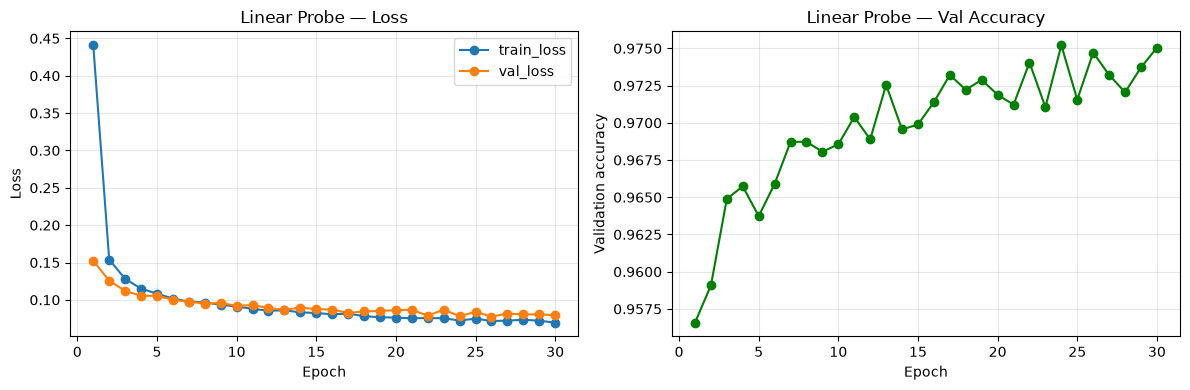

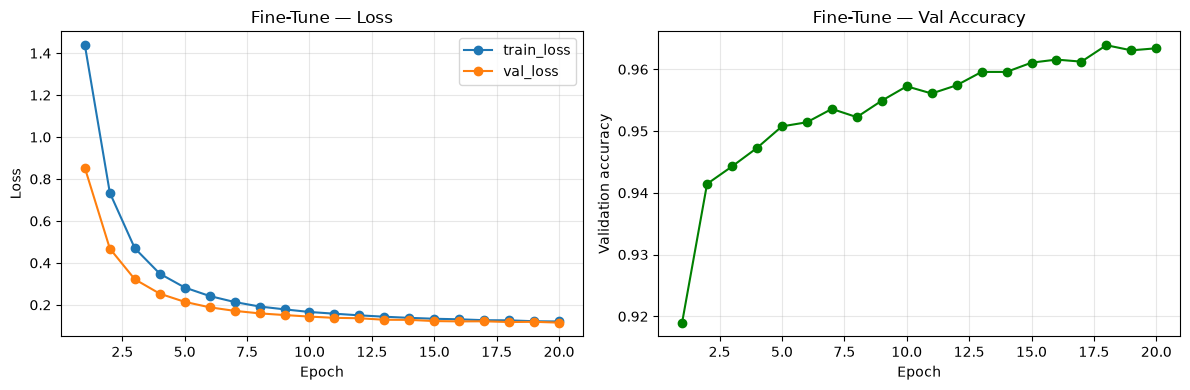

In [17]:
def plot_train_val_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    epochs_range = range(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train_loss")
    if history.get("val_loss"):
        val_epochs_range = range(1, len(history["val_loss"]) + 1)
        axes[0].plot(val_epochs_range, history["val_loss"], marker="o", label="val_loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(range(1, len(history["val_acc"]) + 1), history["val_acc"], marker="o", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Validation accuracy")
    axes[1].set_title(f"{title} — Val Accuracy")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_train_val_history(linear_history, "Linear Probe")
plot_train_val_history(finetune_history, "Fine-Tune")


## 10. Evaluation on Held-Out Test Set

                  precision    recall  f1-score   support

     Anthracnose       0.98      0.97      0.97       710
Bacterial Canker       0.98      0.98      0.98       724
  Cutting Weevil       1.00      0.99      1.00       786
        Die Back       0.99      0.99      0.99       749
      Gall Midge       0.97      0.94      0.95       752
         Healthy       0.96      0.99      0.97       771
  Powdery Mildew       0.97      0.92      0.95       758
     Sooty Mould       0.91      0.96      0.94       727

        accuracy                           0.97      5977
       macro avg       0.97      0.97      0.97      5977
    weighted avg       0.97      0.97      0.97      5977



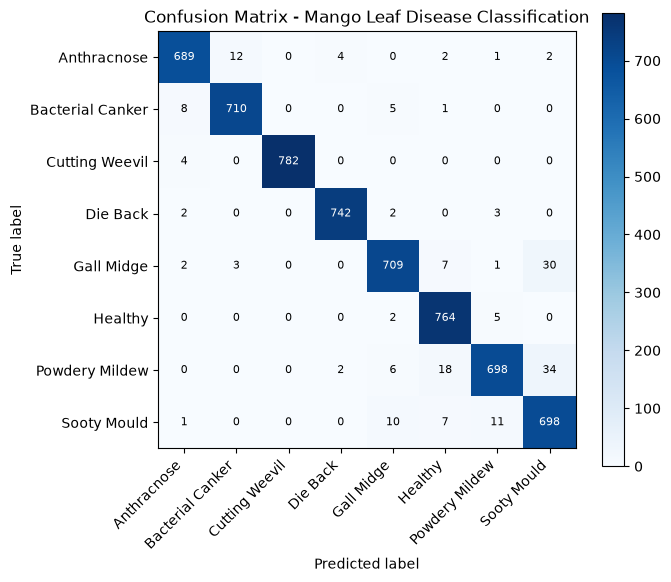

In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools

@torch.no_grad()
def get_predictions(model, loader, device=device):
    model.eval()
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)


y_true, y_pred = get_predictions(finetune_model, test_loader)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - Mango Leaf Disease Classification")
plt.colorbar()
tick_marks = np.arange(len(CLASS_NAMES))
plt.xticks(tick_marks, CLASS_NAMES, rotation=45, ha="right")
plt.yticks(tick_marks, CLASS_NAMES)
thresh = cm.max() / 2.0
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
              color="white" if cm[i, j] > thresh else "black", fontsize=8)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()


## 10b. Alternative Downstream Classifier — XGBoost on Frozen SSL Embeddings

Besides the neural linear probe / fine-tune above, you can train a classical gradient-boosted-tree classifier
directly on the **frozen** SSL embeddings — extract a feature vector per image from `trained_encoder` (no
further training of the encoder itself), then fit XGBoost on those vectors. It's fast (CPU-only, trains in
seconds to minutes rather than epochs), and useful as a cross-check: if XGBoost lands close to the neural
linear-probe accuracy, that's further evidence the embeddings themselves are genuinely informative — a good
classifier design choice showing similar results to a very different one supports the *representation*, not
just one particular classifier's quirks.


In [19]:
# !pip install xgboost -q
import xgboost as xgb
from sklearn.metrics import accuracy_score


@torch.no_grad()
def extract_features(encoder, samples, transform, device=device, batch_size=64):
    ds = MangoLabeledDataset(samples, transform)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)
    encoder.eval()
    feats, labels = [], []
    for imgs, lbls in loader:
        imgs = imgs.to(device)
        h = encoder(imgs)
        feats.append(h.cpu().numpy())
        labels.append(lbls.numpy())
    return np.concatenate(feats), np.concatenate(labels)


print("Extracting frozen SSL embeddings for XGBoost (train/val/test)...")
X_train, y_train = extract_features(trained_encoder, train_samples, eval_transform)
X_val, y_val = extract_features(trained_encoder, val_samples, eval_transform)
X_test, y_test = extract_features(trained_encoder, test_samples, eval_transform)
print(f"Feature shapes -> train: {X_train.shape}  val: {X_val.shape}  test: {X_test.shape}")

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(CLASS_NAMES),
    eval_metric="mlogloss",
    tree_method="hist",  # fast on CPU; switch to "gpu_hist" if your xgboost build has CUDA support
    random_state=SEED,
)

xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=20)

xgb_checkpoint_path = os.path.join(CHECKPOINT_DIR, f"xgboost_{RUN_TAG}.json")
xgb_model.save_model(xgb_checkpoint_path)
print(f"Saved XGBoost model to '{xgb_checkpoint_path}'")


Extracting frozen SSL embeddings for XGBoost (train/val/test)...
Feature shapes -> train: (28012, 512)  val: (6011, 512)  test: (5977, 512)
[0]	validation_0-mlogloss:1.79454
[20]	validation_0-mlogloss:0.35181
[40]	validation_0-mlogloss:0.14096
[60]	validation_0-mlogloss:0.08773
[80]	validation_0-mlogloss:0.06872
[100]	validation_0-mlogloss:0.06106
[120]	validation_0-mlogloss:0.05791
[140]	validation_0-mlogloss:0.05628
[160]	validation_0-mlogloss:0.05586
[180]	validation_0-mlogloss:0.05589
[200]	validation_0-mlogloss:0.05627
[220]	validation_0-mlogloss:0.05668
[240]	validation_0-mlogloss:0.05683
[260]	validation_0-mlogloss:0.05693
[280]	validation_0-mlogloss:0.05718
[299]	validation_0-mlogloss:0.05777
Saved XGBoost model to 'checkpoints\xgboost_simclr_resnet18.json'


XGBoost test accuracy: 0.9829
                  precision    recall  f1-score   support

     Anthracnose       0.97      0.99      0.98       710
Bacterial Canker       0.99      0.99      0.99       724
  Cutting Weevil       1.00      0.99      1.00       786
        Die Back       0.99      1.00      0.99       749
      Gall Midge       0.99      0.96      0.98       752
         Healthy       0.98      0.99      0.99       771
  Powdery Mildew       0.98      0.97      0.97       758
     Sooty Mould       0.95      0.98      0.96       727

        accuracy                           0.98      5977
       macro avg       0.98      0.98      0.98      5977
    weighted avg       0.98      0.98      0.98      5977



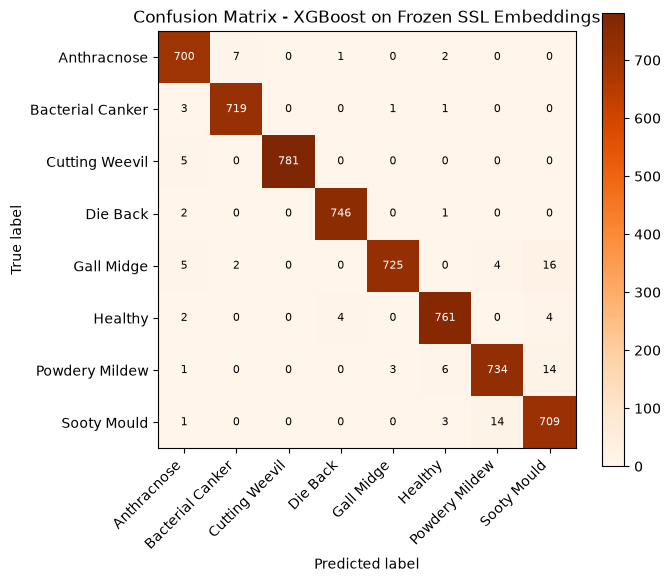


Comparison on the same held-out test set:
  Fine-tuned neural network:  0.9690
  XGBoost on frozen embeddings: 0.9829


In [20]:
y_pred_xgb = xgb_model.predict(X_test)
xgb_test_acc = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost test accuracy: {xgb_test_acc:.4f}")
print(classification_report(y_test, y_pred_xgb, target_names=CLASS_NAMES, zero_division=0))

cm_xgb = confusion_matrix(y_test, y_pred_xgb, labels=range(len(CLASS_NAMES)))

plt.figure(figsize=(7, 6))
plt.imshow(cm_xgb, cmap="Oranges")
plt.title("Confusion Matrix - XGBoost on Frozen SSL Embeddings")
plt.colorbar()
tick_marks = np.arange(len(CLASS_NAMES))
plt.xticks(tick_marks, CLASS_NAMES, rotation=45, ha="right")
plt.yticks(tick_marks, CLASS_NAMES)
thresh = cm_xgb.max() / 2.0
for i, j in itertools.product(range(cm_xgb.shape[0]), range(cm_xgb.shape[1])):
    plt.text(j, i, format(cm_xgb[i, j], "d"), ha="center", va="center",
              color="white" if cm_xgb[i, j] > thresh else "black", fontsize=8)
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

# Quick side-by-side vs. the neural classifiers evaluated above
nn_test_acc = (y_pred == y_true).mean()
print(f"\nComparison on the same held-out test set:")
print(f"  Fine-tuned neural network:  {nn_test_acc:.4f}")
print(f"  XGBoost on frozen embeddings: {xgb_test_acc:.4f}")


## 11. Visualizing the Learned Embedding Space (t-SNE)

A good SSL encoder should already separate healthy vs. diseased/stressed mango leaves in embedding space, even
before any labels are used for classification.


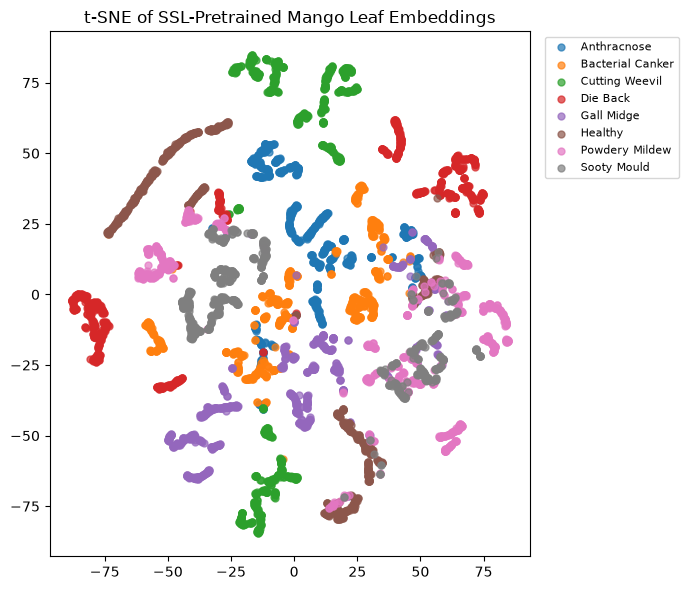

In [21]:
from sklearn.manifold import TSNE

@torch.no_grad()
def get_embeddings(encoder, loader, device=device):
    encoder.eval()
    feats, labels_out = [], []
    for imgs, labels in loader:
        imgs = imgs.to(device)
        h = encoder(imgs)
        feats.append(h.cpu().numpy())
        labels_out.append(labels.numpy())
    return np.concatenate(feats), np.concatenate(labels_out)


embeds, labels_arr = get_embeddings(trained_encoder, test_loader)

n_samples = embeds.shape[0]
perplexity = max(5, min(30, n_samples // 3)) if n_samples > 5 else 2
tsne = TSNE(n_components=2, random_state=SEED, perplexity=perplexity, init="pca")
embeds_2d = tsne.fit_transform(embeds)

plt.figure(figsize=(7, 6))
for idx, cname in enumerate(CLASS_NAMES):
    mask = labels_arr == idx
    if mask.sum() > 0:
        plt.scatter(embeds_2d[mask, 0], embeds_2d[mask, 1], label=cname, alpha=0.7, s=25)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.title("t-SNE of SSL-Pretrained Mango Leaf Embeddings")
plt.tight_layout()
plt.show()


## 12. Early Stress Scoring — Distance From "Healthy" Centroid

Beyond classification, the SSL embedding space itself can be used for **early stress detection**: compute the
centroid of embeddings for known-healthy leaves, then score any new leaf image by its distance to that centroid.
A leaf drifting away from the healthy cluster — even before it's confidently classified into a specific disease
category — can be flagged as an **early / ambiguous stress signal** for closer inspection.


Treating class 'Healthy' as the healthy reference class.
Flagged 5977 / 5977 test images as showing early stress signal (distance > 1.28 from healthy centroid)


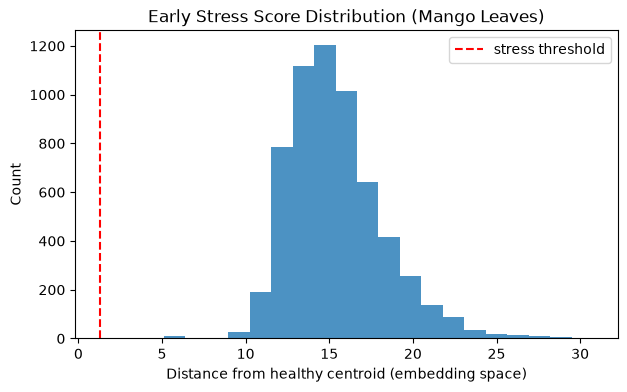

In [22]:
healthy_candidates = [i for i, c in enumerate(CLASS_NAMES) if "healthy" in c.lower()]
HEALTHY_IDX = healthy_candidates[0] if healthy_candidates else 0
print(f"Treating class '{CLASS_NAMES[HEALTHY_IDX]}' as the healthy reference class.")


@torch.no_grad()
def compute_healthy_centroid(encoder, samples, transform, healthy_idx=HEALTHY_IDX, device=device):
    healthy_samples = [s for s in samples if s[1] == healthy_idx]
    ds = MangoLabeledDataset(healthy_samples, transform)
    loader = DataLoader(ds, batch_size=32, shuffle=False)
    feats, _ = get_embeddings(encoder, loader, device)
    centroid = feats.mean(axis=0)
    return centroid, feats.std(axis=0).mean()  # centroid + a rough spread estimate


healthy_centroid, healthy_spread = compute_healthy_centroid(trained_encoder, train_samples, eval_transform)


@torch.no_grad()
def stress_score(encoder, image_path, centroid, transform, device=device):
    img = Image.open(image_path).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    encoder.eval()
    feat = encoder(x).cpu().numpy()[0]
    dist = np.linalg.norm(feat - centroid)
    return dist


# Example: score every test image and flag ones that drift far from "healthy"
scores = [stress_score(trained_encoder, path, healthy_centroid, eval_transform) for path, _ in test_samples]
scores = np.array(scores)
threshold = healthy_spread * 3  # simple heuristic threshold, tune on a validation set in practice

flagged = scores > threshold
print(f"Flagged {flagged.sum()} / {len(scores)} test images as showing early stress signal "
      f"(distance > {threshold:.2f} from healthy centroid)")

plt.figure(figsize=(7, 4))
plt.hist(scores, bins=20, alpha=0.8)
plt.axvline(threshold, color="red", linestyle="--", label="stress threshold")
plt.xlabel("Distance from healthy centroid (embedding space)")
plt.ylabel("Count")
plt.title("Early Stress Score Distribution (Mango Leaves)")
plt.legend()
plt.show()


## 13. Save Final Artifacts

The per-epoch checkpoints in `checkpoints/` already contain everything needed to resume training. This cell
additionally exports clean, inference-ready weight files (no optimizer state) for deployment.


In [23]:
torch.save(trained_encoder.state_dict(), os.path.join(CHECKPOINT_DIR, f"mango_ssl_encoder_final_{RUN_TAG}.pt"))
torch.save(finetune_model.state_dict(), os.path.join(CHECKPOINT_DIR, f"mango_disease_classifier_final_{RUN_TAG}.pt"))
print("Saved final inference weights to:")
print(" -", os.path.join(CHECKPOINT_DIR, f"mango_ssl_encoder_final_{RUN_TAG}.pt"))
print(" -", os.path.join(CHECKPOINT_DIR, f"mango_disease_classifier_final_{RUN_TAG}.pt"))


Saved final inference weights to:
 - checkpoints\mango_ssl_encoder_final_simclr_resnet18.pt
 - checkpoints\mango_disease_classifier_final_simclr_resnet18.pt


## 14. Conclusion & Next Steps

This notebook implemented an end-to-end **self-supervised learning framework for mango leaf stress/disease
detection**, designed to run locally with resumable progress:

- Auto-downloads the **Combined Mango Leaf Disease Dataset** from Kaggle (`binhpt310/mango-combined-dataset`) via
  `kagglehub`, with a synthetic fallback if offline / not yet authenticated.
- Pretrained a configurable ResNet backbone with **SimCLR or BYOL contrastive learning** on unlabeled mango leaves.
- Fine-tuned a neural classifier for 8-class mango disease detection, plus an **XGBoost classifier on the
  frozen embeddings** as an independent cross-check.
- Visualized the learned embedding space with t-SNE.
- Built a simple **early-stress scoring** mechanism using distance-from-healthy-centroid in embedding space.
- **Checkpointed every training stage to disk**, auto-resuming on re-run so nothing is lost between sessions.

**To get stronger results:**
- Increase `EPOCHS_SSL` and the downstream `epochs` substantially (SimCLR typically wants 100+ epochs).
- Add more unlabeled mango images from other sources (e.g. PlantDoc's mango subset) to the SSL pretraining pool
  to improve representation quality, even without extra labels.
- Swap SimCLR for **BYOL** or **DINO** (no negative pairs needed, often more robust with small batch sizes).
- Add domain-specific augmentations for field imagery (lighting/exposure jitter, leaf-angle simulation).
- Calibrate the stress-score threshold using a held-out validation set of leaves at known early disease stages.
